# Principal Component Analysis (PCA) for Biochar py-GC-MS Data:

### Imports & Directory Initialisation:

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import os

save_dir = os.getcwd()
save_png = os.path.join(save_dir, 'PNG')
save_tiff = os.path.join(save_dir, 'TIFF')
save_csv = os.path.join(save_dir, 'CSV')

os.makedirs(save_png, exist_ok=True)
os.makedirs(save_tiff, exist_ok=True)
os.makedirs(save_csv, exist_ok=True)

### Inspecting Data:

In [19]:
CSV_PATH = r"data/biochar-PCA-18112026.csv"

# Create Pandas dataframe of CSV file:
df = pd.read_csv(CSV_PATH, index_col=0)
print("Loaded data shape (molecules x samples):", df.shape)

df.head(10) # print first 10 entries of dataframe

Loaded data shape (molecules x samples): (53, 11)


,Murchison,L,TM,CW,CN,PB400,PB500,PB700,CW400,CW500,CW700
n-alkane/n-alkene,-0.534540,-0.534540,0.393180,1.841192,-0.534540,2.041949,-0.534540,-0.534540,-0.534540,-0.534540,-0.534540
Benzene,-0.287536,-0.842622,-0.549171,-1.227623,-0.777842,-0.210950,1.555011,0.715369,-0.487199,1.878015,0.234547
Thiophene,3.015113,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511
C1-Benzene,-1.236085,-0.052394,-1.404830,-0.720678,1.244865,-1.144344,0.101870,1.123473,0.588517,0.317434,1.182171
C1-Thiophene,3.013630,-0.207261,-0.311819,-0.311819,-0.311819,-0.311819,-0.311819,-0.311819,-0.311819,-0.311819,-0.311819
C2-Benzene,1.259079,-0.017521,1.279618,0.969624,-1.157557,0.551435,0.301534,-1.157557,0.286460,-1.157557,-1.157557
C2-Thiophene,3.015113,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511
C3-Benzene,1.852106,-0.646485,1.438882,1.273549,-0.704048,-0.156803,-0.525268,-0.704048,-0.419789,-0.704048,-0.704048
C3-Thiophene,3.015113,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511,-0.301511
Phenol,-0.461566,1.571771,-0.685298,-0.240503,-1.118440,1.228365,1.024989,-1.118440,0.625895,0.291666,-1.118440


### Scree Plot: Deciding How Many PC's

The 'elbow point' of a Scree plot indicates the optimal number of principal components (PCs) to plot and evaluate in PC-space.

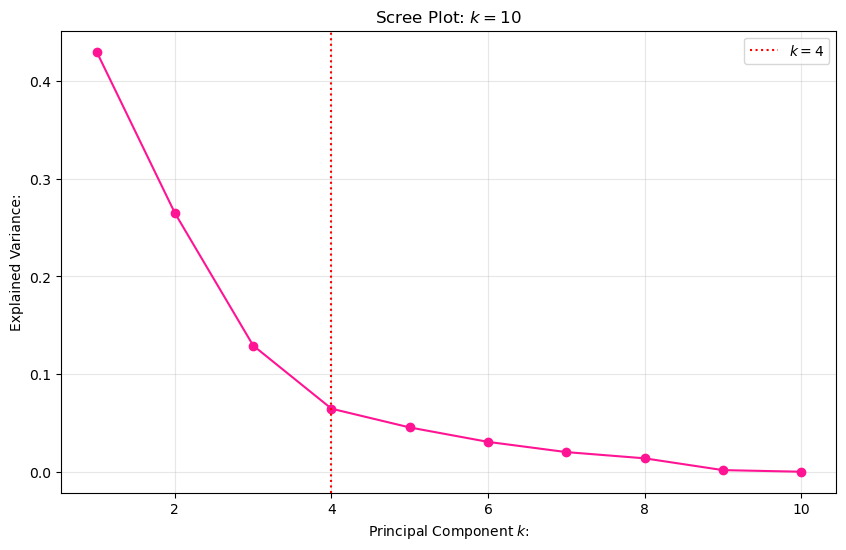

In [20]:
data_for_pca = df.T
sample_names = data_for_pca.index.tolist()
molecule_names = data_for_pca.columns.tolist()

X = data_for_pca.values  # feature matrix

# Initialise PCs
k = 10
pca = PCA(n_components=k)

# Reduce data into k = 10:
scores = pca.fit_transform(X)
explained_var = pca.explained_variance_ratio_
cum_var = explained_var.cumsum()

# Scree Plot:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker="o", color="deeppink")
plt.xlabel(f"Principal Component $k$:")
plt.ylabel("Explained Variance:")
plt.axvline(4.0, linestyle=":", color="r", label=f"$k = 4$")
plt.legend()
plt.title(f"Scree Plot: $k = {k}$")
plt.grid(True, alpha=0.3)
plt.show()

Clearly, $k=4$ (indicated by the red dashed line) is the optimal number of PC's needed to accurately reflect the data and perform PCA. Hence, only $4$ principal component's will be considered for subsequent analysis.

### Performing PCA: $k=4$

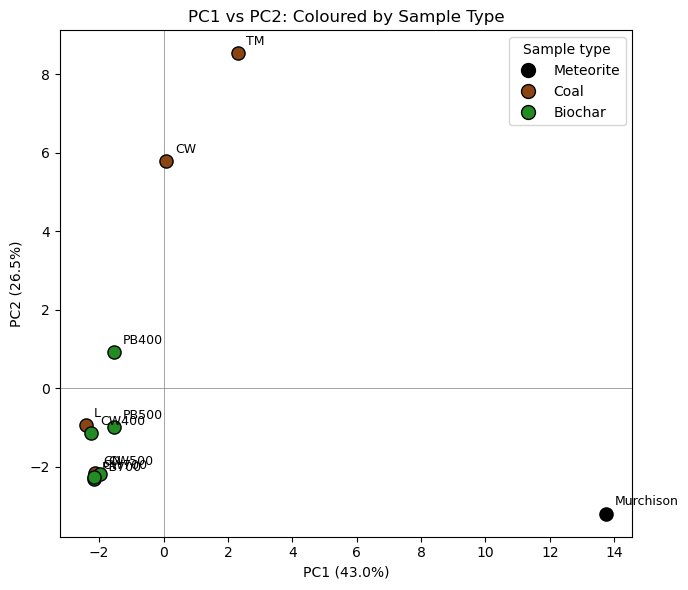

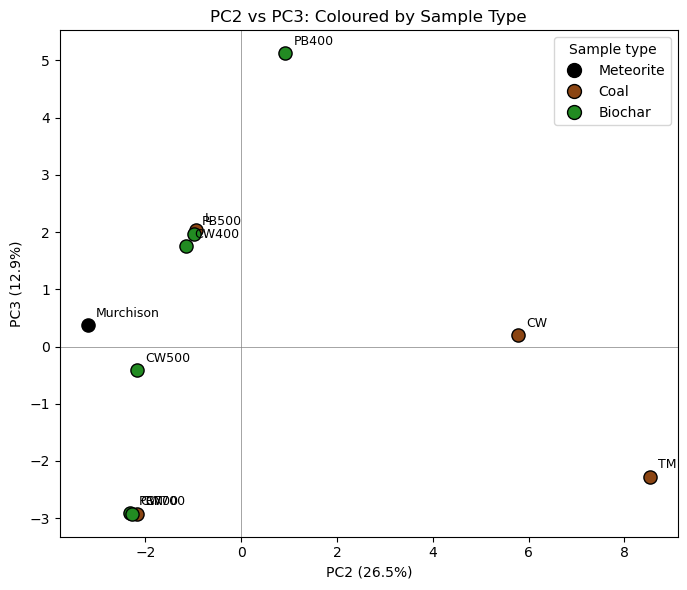

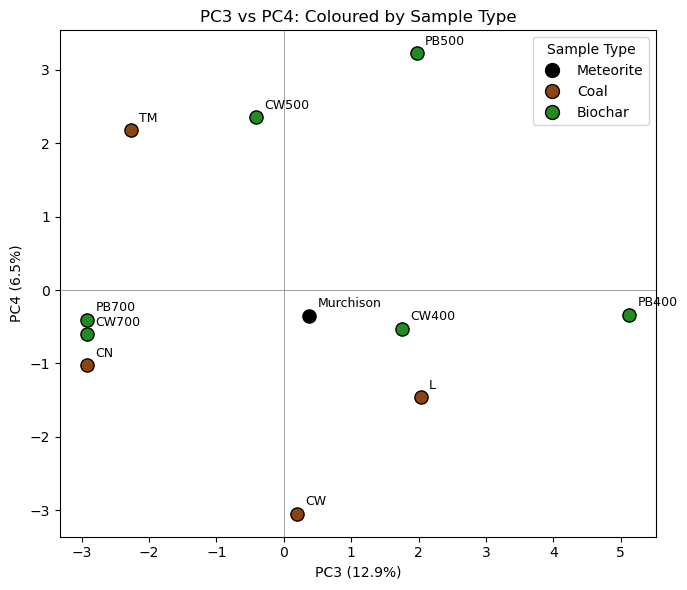

In [21]:
# Defining sample groupings:
sample_groups = {
    "Murchison": "Meteorite",
    "L": "Coal", "TM": "Coal", "CW": "Coal", "CN": "Coal",
    "PB400": "Biochar", "PB500": "Biochar", "PB700": "Biochar",
    "CW400": "Biochar", "CW500": "Biochar", "CW700": "Biochar",
}
group_colors = {"Meteorite": "black", "Coal": "saddlebrown", "Biochar": "forestgreen"}

# Plotting & formatting: PC1-PC2
fig, ax = plt.subplots(figsize=(7, 6))
for i, name in enumerate(sample_names):
    group = sample_groups.get(name, "Other")
    color = group_colors.get(group, "gray")
    ax.scatter(scores[i, 0], scores[i, 1], color=color, s=90, edgecolor="k", zorder=3)
    ax.annotate(name, (scores[i, 0], scores[i, 1]), textcoords="offset points",
                xytext=(6, 6), fontsize=9)

ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"PC1 ({(explained_var[0]*100):.1f}%)")
ax.set_ylabel(f"PC2 ({(explained_var[1]*100):.1f}%)")
ax.set_title("PC1 vs PC2: Coloured by Sample Type")


handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c,
                      markeredgecolor="k", markersize=10, label=g)
           for g, c in group_colors.items()]
ax.legend(handles=handles, title="Sample type")
plt.tight_layout()
plt.savefig(os.path.join(save_png, "scores_plot_PC1_PC2.png"), dpi=300)
plt.savefig(os.path.join(save_tiff, "scores_plot_PC1_PC2.tiff"), dpi=300)
plt.show()

# Plotting & formatting: PC2-PC3
if cum_var[1] < 70 and len(explained_var) >= 3:
    fig, ax = plt.subplots(figsize=(7, 6))
    for i, name in enumerate(sample_names):
        group = sample_groups.get(name, "Other")
        color = group_colors.get(group, "gray")
        ax.scatter(scores[i, 1], scores[i, 2], color=color, s=90, edgecolor="k", zorder=3)
        ax.annotate(name, (scores[i, 1], scores[i, 2]), textcoords="offset points",
                    xytext=(6, 6), fontsize=9)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlabel(f"PC2 ({(explained_var[1]*100):.1f}%)")
    ax.set_ylabel(f"PC3 ({(explained_var[2]*100):.1f}%)")
    ax.set_title("PC2 vs PC3: Coloured by Sample Type")
    ax.legend(handles=handles, title="Sample type")
    plt.tight_layout()
    plt.savefig(os.path.join(save_png, "scores_plot_PC2_PC3.png"), dpi=300)
    plt.savefig(os.path.join(save_tiff, "scores_plot_PC2_PC3.tiff"), dpi=300)
    plt.show()

# Plotting & formatting: PC3-PC4
if cum_var[2] < 90 and len(explained_var) >= 4:
    fig, ax = plt.subplots(figsize=(7, 6))
    for i, name in enumerate(sample_names):
        group = sample_groups.get(name, "Other")
        color = group_colors.get(group, "gray")
        ax.scatter(scores[i, 2], scores[i, 3], color=color, s=90, edgecolor="k", zorder=3)
        ax.annotate(name, (scores[i, 2], scores[i, 3]), textcoords="offset points",
                    xytext=(6, 6), fontsize=9)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlabel(f"PC3 ({(explained_var[2]*100):.1f}%)")
    ax.set_ylabel(f"PC4 ({(explained_var[3]*100):.1f}%)")
    ax.set_title("PC3 vs PC4: Coloured by Sample Type")
    ax.legend(handles=handles, title="Sample Type")
    plt.tight_layout()
    plt.savefig(os.path.join(save_png, "scores_plot_PC3_PC4.png"), dpi=300)
    plt.savefig(os.path.join(save_tiff, "scores_plot_PC3_PC4.tiff"), dpi=300)
    plt.show()

### PCA Loadings:

To calculate the variance-scaled loadings of a given PC, one can use the following equation (Chouinard 2023):

$$\text{Loadings} = \phi \times \sqrt{\lambda} \; \; \; \; \; \; \; \; \; \; \; \; \;(1)$$

where $\phi$ are the eigenvectors (i.e., the directions of the PCs) of the covariance matrix formed from the calculated covariance of every pair of features, and $\lambda$ are the eigenvalues capturing the magnitude of the corresponding $\phi$.

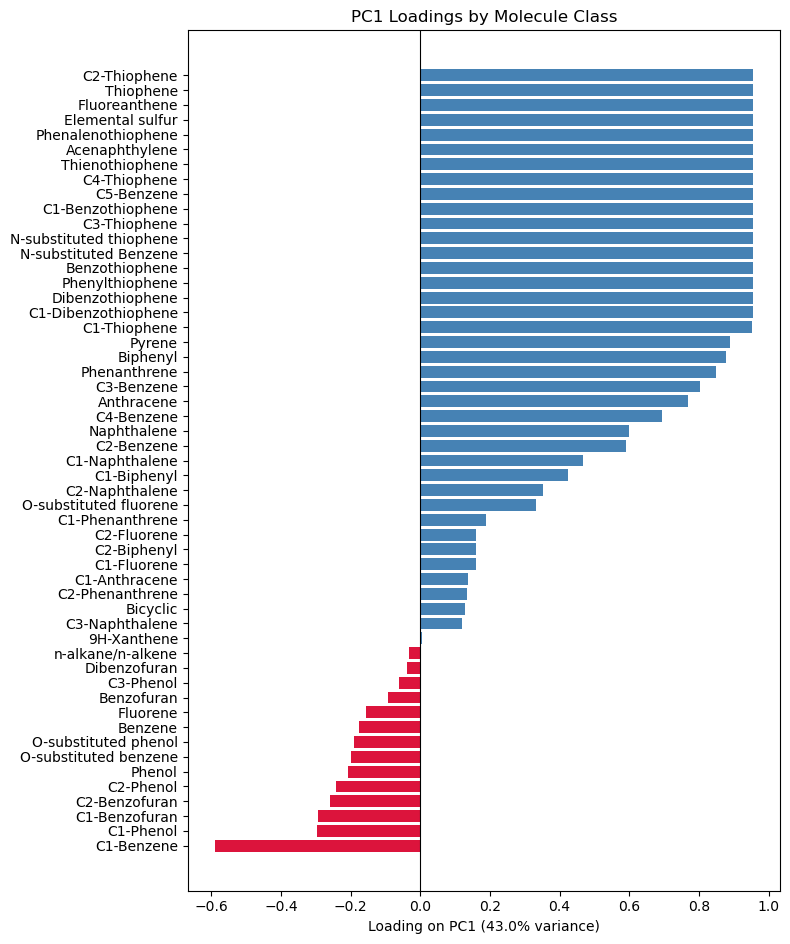

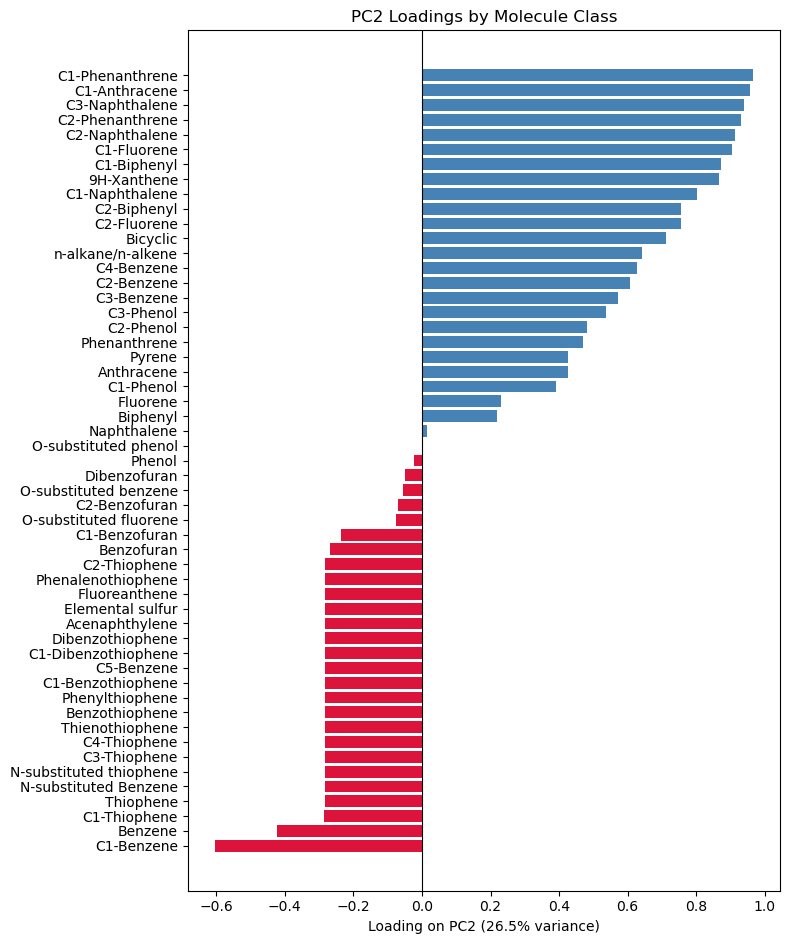

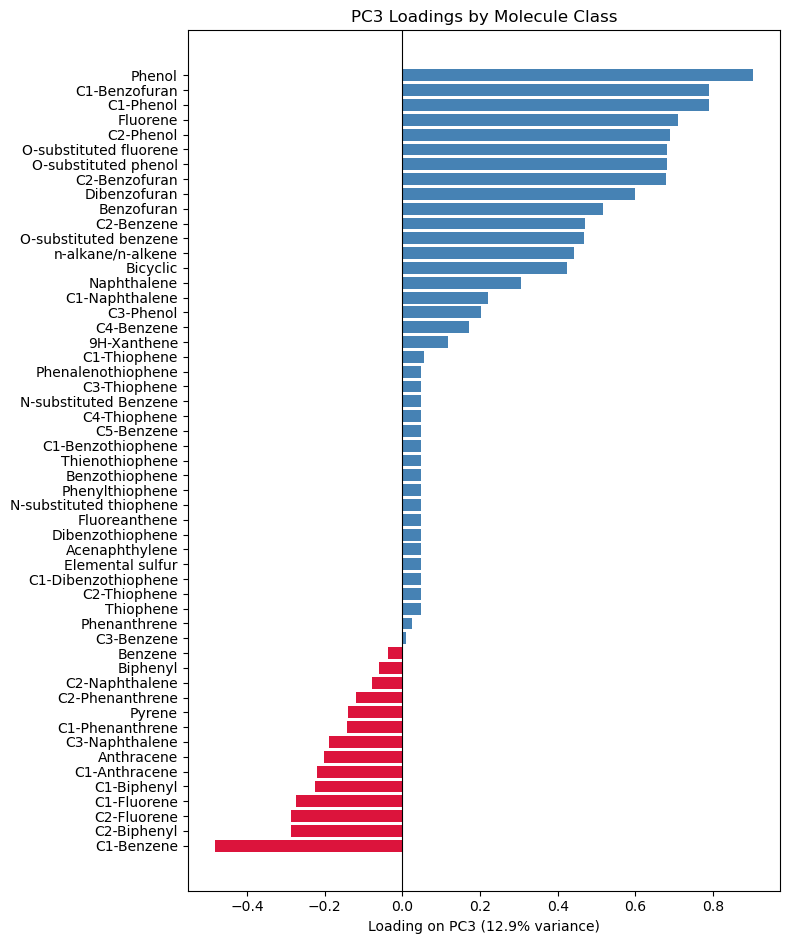

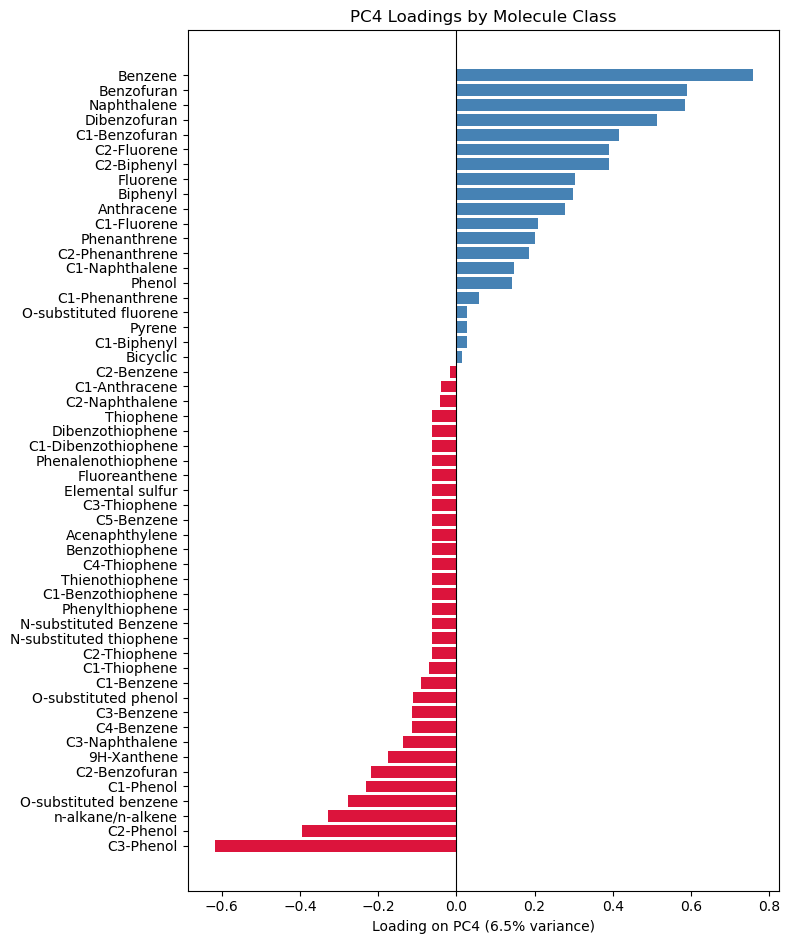


Saved: scree_plot.png, scores_plot_PC1_PC2.png, loadings_PC1.png, loadings_PC2.png, loadings_PC3.png,
       scree_plot.tiff, scores_plot_PC1_PC2.tiff, loadings_PC1.tiff, loadings_PC2.tiff, loadings_PC3.tiff,
       pca_scores.csv, pca_loadings.csv
       All files saved to relevant folders in c:\Users\lette\OneDrive\Desktop\Imperial PhD\Year 1\ICOG-help\pca-pygcms


In [22]:
# Calculate loadings using equation (1):
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)  # already transposed

N_PCS_TO_PLOT = 4  # based on previous scree plot analysis

for pc_idx in range(N_PCS_TO_PLOT):
    loading_series = pd.Series(loadings[:, pc_idx], index=molecule_names)
    loading_series_sorted = loading_series.sort_values()

    plt.figure(figsize=(8, max(6, len(molecule_names) * 0.18)))
    colors = ["crimson" if v < 0 else "steelblue" for v in loading_series_sorted]
    plt.barh(loading_series_sorted.index, loading_series_sorted.values, color=colors)
    plt.axvline(0, color="black", lw=0.8)
    plt.xlabel(f"Loading on PC{pc_idx + 1} ({(explained_var[pc_idx]*100):.1f}% variance)")
    plt.title(f"PC{pc_idx + 1} Loadings by Molecule Class")
    plt.tight_layout()
    plt.savefig(os.path.join(save_png, f"loadings_PC{pc_idx + 1}.png"), dpi=300)
    plt.savefig(os.path.join(save_tiff, f"loadings_PC{pc_idx + 1}.tiff"), dpi=300)
    plt.show()


scores_df = pd.DataFrame(scores, index=sample_names,
                          columns=[f"PC{i+1}" for i in range(scores.shape[1])])
scores_df.to_csv(os.path.join(save_csv, "pca_scores.csv"))

loadings_df = pd.DataFrame(loadings, index=molecule_names,  # no need to transpose again
                            columns=[f"PC{i+1}" for i in range(loadings.shape[1])])
loadings_df.to_csv(os.path.join(save_csv, "pca_loadings.csv"))

print("\nSaved: scree_plot.png, scores_plot_PC1_PC2.png, loadings_PC1.png, loadings_PC2.png, loadings_PC3.png,")
print("       scree_plot.tiff, scores_plot_PC1_PC2.tiff, loadings_PC1.tiff, loadings_PC2.tiff, loadings_PC3.tiff,")
print("       pca_scores.csv, pca_loadings.csv")
print(f"       All files saved to relevant folders in {save_dir}")

### Bibliography:

Chouinard, J. C. (2023). *What are PCA Loadings (with Python Example)*. https://www.jcchouinard.com/pca-loadings/